In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Environment setup successful!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)



Environment setup successful!
Pandas version: 2.3.3
NumPy version: 2.1.3
Scikit-learn version: 1.6.1


In [2]:

import os

for folder, subfolders, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(folder, file))


/kaggle/input/datasets/chandanabonbon/airqualityuci-csv/AirQualityUCI.csv
/kaggle/input/datasets/chandanabonbon/airqualityuci-csv/AirQualityUCI.xlsx


In [4]:

import glob

files = glob.glob(
    "/kaggle/input/**/AirQualityUCI.csv",
    recursive=True
)

if not files:
    raise FileNotFoundError("AirQualityUCI.csv not found")

df = pd.read_csv(
    files[0],
    sep=";",
    decimal=","
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Shape: (9471, 17)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN


In [5]:

df_clean = df.copy()

df_clean = df_clean.dropna(axis=1, how="all")

df_clean = df_clean.dropna(
    subset=["Date", "Time"]
)

df_clean = df_clean.reset_index(drop=True)

print("Cleaned shape:", df_clean.shape)


Cleaned shape: (9357, 15)


In [6]:

df_clean["Datetime"] = pd.to_datetime(
    df_clean["Date"] + " " +
    df_clean["Time"].str.replace(
        ".", ":", regex=False
    ),
    format="%d/%m/%Y %H:%M:%S"
)

df_clean = df_clean.sort_values("Datetime")

df_clean = df_clean.drop(
    columns=["Date", "Time"]
)

df_clean = df_clean.set_index("Datetime")

print("Start:", df_clean.index.min())
print("End:", df_clean.index.max())


Start: 2004-03-10 18:00:00
End: 2005-04-04 14:00:00


In [7]:

df_clean = df_clean.replace(-200, np.nan)

missing_report = pd.DataFrame({
    "Missing Count": df_clean.isna().sum(),
    "Missing %": (
        df_clean.isna().mean() * 100
    ).round(2)
})

display(
    missing_report.sort_values(
        "Missing %",
        ascending=False
    )
)


,Missing Count,Missing %
NMHC(GT),8443,90.23
CO(GT),1683,17.99
NO2(GT),1642,17.55
NOx(GT),1639,17.52
PT08.S1(CO),366,3.91
PT08.S2(NMHC),366,3.91
C6H6(GT),366,3.91
PT08.S3(NOx),366,3.91
PT08.S4(NO2),366,3.91
PT08.S5(O3),366,3.91


In [8]:

df_clean = df_clean.drop(
    columns=["NMHC(GT)"]
)

print(df_clean.shape)


(9357, 12)


In [9]:

print(
    "Duplicate timestamps:",
    df_clean.index.duplicated().sum()
)

expected_hours = pd.date_range(
    start=df_clean.index.min(),
    end=df_clean.index.max(),
    freq="h"
)

missing_hours = expected_hours.difference(
    df_clean.index
)

print("Missing hourly timestamps:", len(missing_hours))


Duplicate timestamps: 0
Missing hourly timestamps: 0


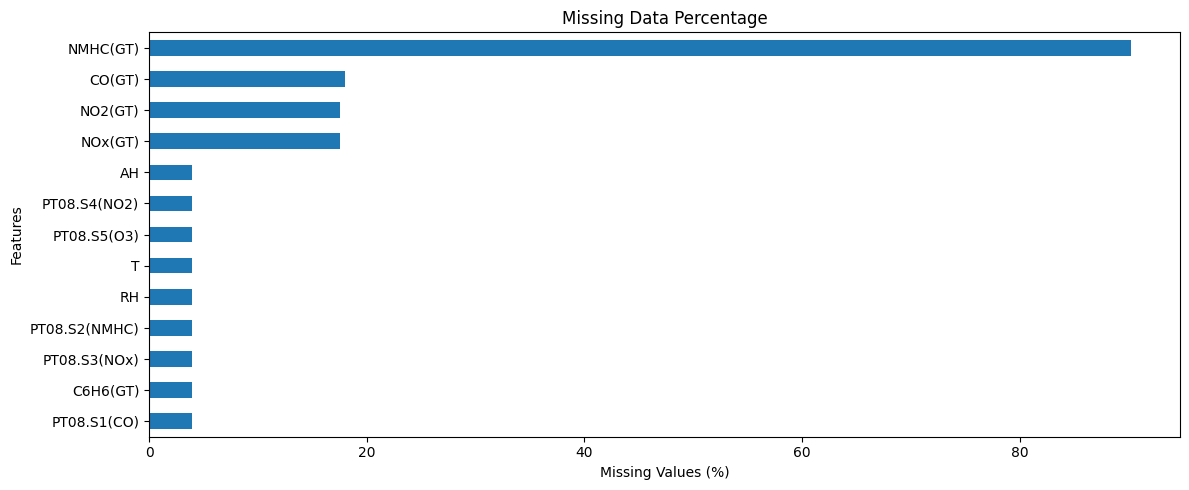

In [10]:

plt.figure(figsize=(12, 5))

missing_report["Missing %"].sort_values().plot(
    kind="barh"
)

plt.title("Missing Data Percentage")
plt.xlabel("Missing Values (%)")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


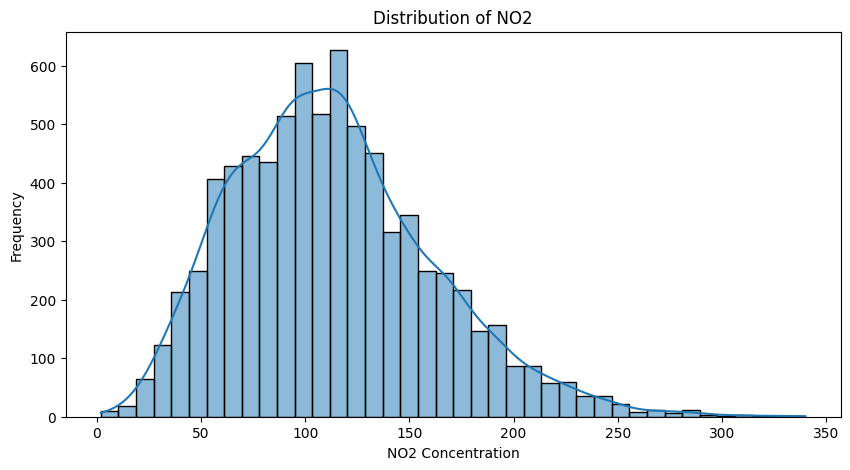

In [11]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x="NO2(GT)",
    bins=40,
    kde=True
)

plt.title("Distribution of NO2")
plt.xlabel("NO2 Concentration")
plt.ylabel("Frequency")
plt.show()


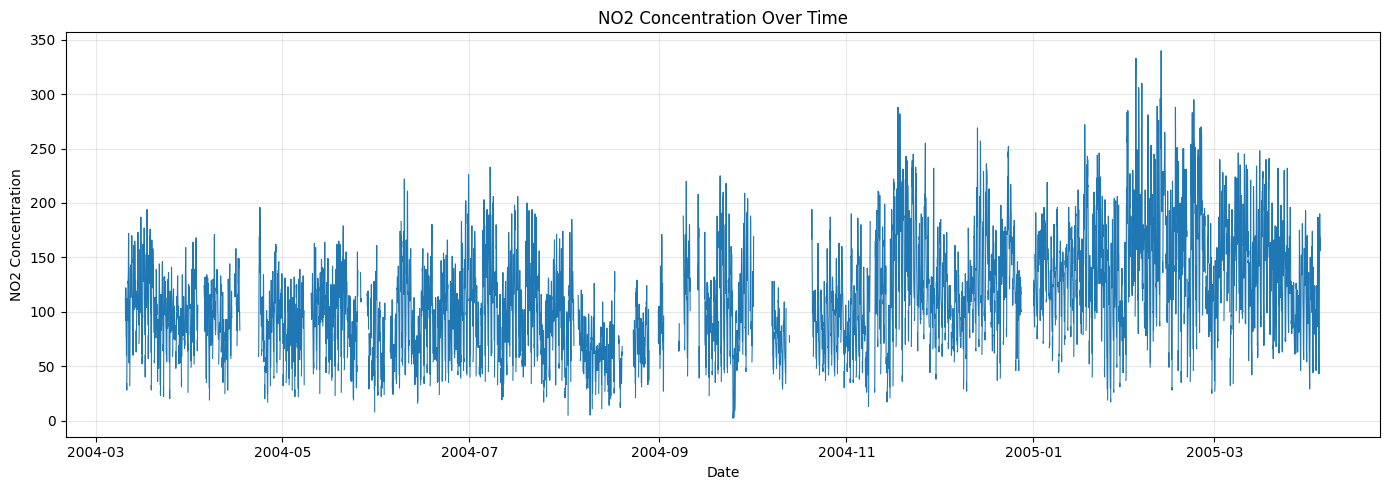

In [12]:

plt.figure(figsize=(14, 5))

plt.plot(
    df_clean.index,
    df_clean["NO2(GT)"],
    linewidth=0.8
)

plt.title("NO2 Concentration Over Time")
plt.xlabel("Date")
plt.ylabel("NO2 Concentration")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


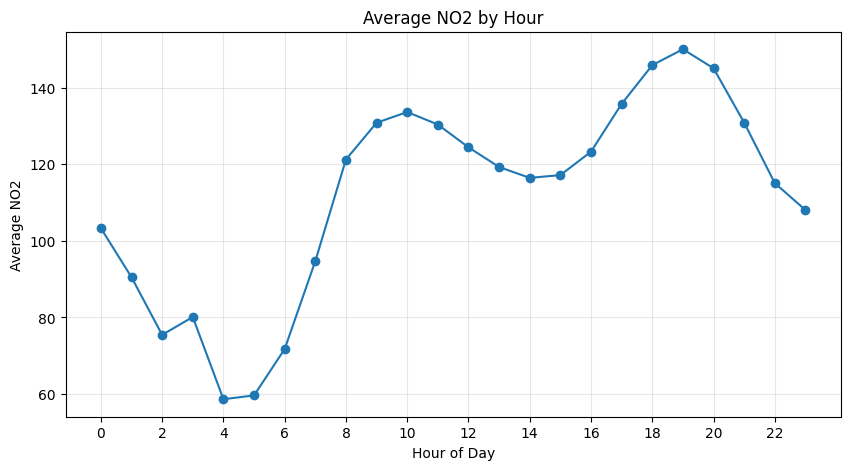

In [13]:

hourly_no2 = df_clean.groupby(
    df_clean.index.hour
)["NO2(GT)"].mean()

plt.figure(figsize=(10, 5))

hourly_no2.plot(marker="o")

plt.title("Average NO2 by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average NO2")
plt.xticks(range(0, 24, 2))
plt.grid(alpha=0.3)
plt.show()


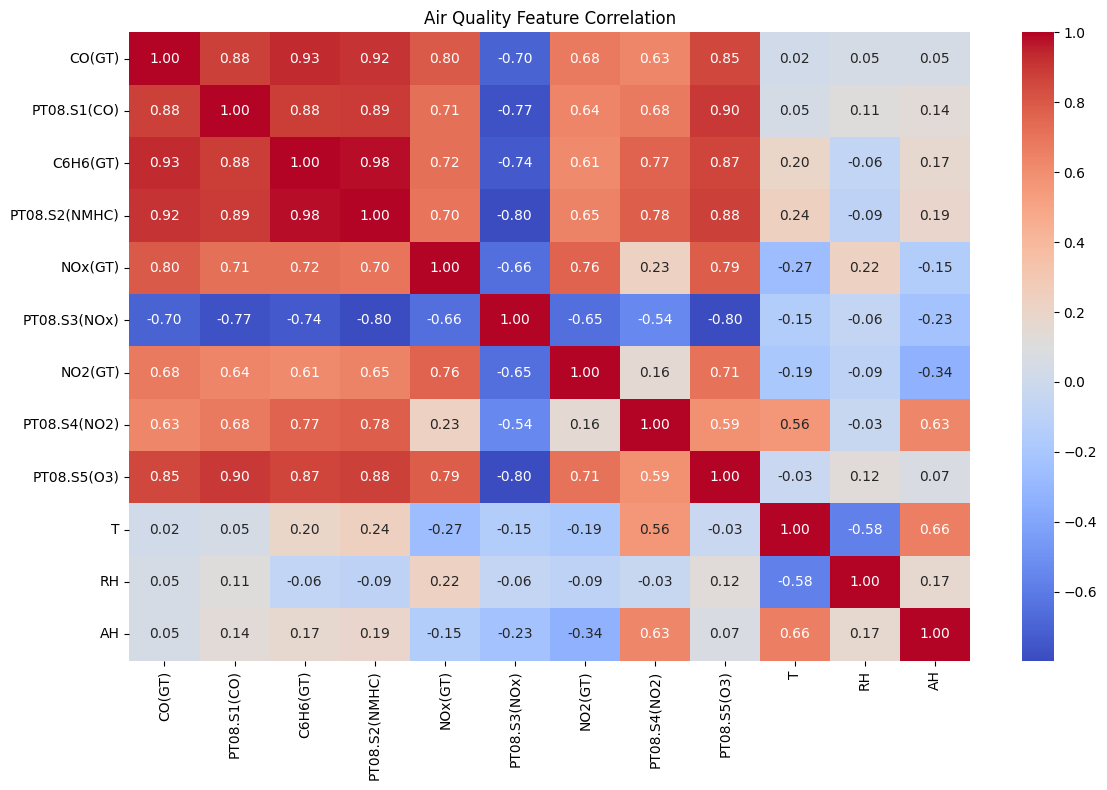

In [14]:

plt.figure(figsize=(12, 8))

correlation = df_clean.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Air Quality Feature Correlation")
plt.tight_layout()
plt.show()


In [15]:

# Keep a separate copy for modeling
model_df = df_clean.copy()

# Verify there are no duplicate timestamps
assert not model_df.index.has_duplicates

# Create a continuous hourly index
model_df = model_df.asfreq("h")

print("Modeling shape:", model_df.shape)
print("Missing timestamps handled as NaN")


Modeling shape: (9357, 12)
Missing timestamps handled as NaN


In [16]:

# Calendar features
model_df["hour"] = model_df.index.hour
model_df["day_of_week"] = model_df.index.dayofweek

# Previous NO2 measurements
model_df["no2_lag_1"] = model_df["NO2(GT)"].shift(1)
model_df["no2_lag_3"] = model_df["NO2(GT)"].shift(3)
model_df["no2_lag_24"] = model_df["NO2(GT)"].shift(24)

# Average NO2 over the preceding 6 hours
model_df["no2_rolling_6"] = (
    model_df["NO2(GT)"]
    .shift(1)
    .rolling(window=6, min_periods=3)
    .mean()
)

# Previous-hour environmental measurements
for column in ["T", "RH", "AH"]:
    model_df[column + "_lag_1"] = (
        model_df[column].shift(1)
    )

# Previous-hour sensor measurements
for column in ["PT08.S3(NOx)", "PT08.S4(NO2)"]:
    model_df[column + "_lag_1"] = (
        model_df[column].shift(1)
    )

display(model_df.head(8))


,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,...,day_of_week,no2_lag_1,no2_lag_3,no2_lag_24,no2_rolling_6,T_lag_1,RH_lag_1,AH_lag_1,PT08.S3(NOx)_lag_1,PT08.S4(NO2)_lag_1
Datetime,,,,,,,,,,,,,,,,,,,,,
2004-03-10 18:00:00,2.6,1360.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,...,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2004-03-10 19:00:00,2.0,1292.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,...,2,113.0,NaN,NaN,NaN,13.6,48.9,0.7578,1056.0,1692.0
2004-03-10 20:00:00,2.2,1402.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,...,2,92.0,NaN,NaN,NaN,13.3,47.7,0.7255,1174.0,1559.0
2004-03-10 21:00:00,2.2,1376.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,...,2,114.0,113.0,NaN,106.333333,11.9,54.0,0.7502,1140.0,1555.0
2004-03-10 22:00:00,1.6,1272.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,...,2,122.0,92.0,NaN,110.250000,11.0,60.0,0.7867,1092.0,1584.0
2004-03-10 23:00:00,1.2,1197.0,4.7,750.0,89.0,1337.0,96.0,1393.0,949.0,11.2,...,2,116.0,114.0,NaN,111.400000,11.2,59.6,0.7888,1205.0,1490.0
2004-03-11 00:00:00,1.2,1185.0,3.6,690.0,62.0,1462.0,77.0,1333.0,733.0,11.3,...,3,96.0,122.0,NaN,108.833333,11.2,59.2,0.7848,1337.0,1393.0
2004-03-11 01:00:00,1.0,1136.0,3.3,672.0,62.0,1453.0,76.0,1333.0,730.0,10.7,...,3,77.0,116.0,NaN,102.833333,11.3,56.8,0.7603,1462.0,1333.0


In [17]:

features = [
    "hour",
    "day_of_week",
    "no2_lag_1",
    "no2_lag_3",
    "no2_lag_24",
    "no2_rolling_6",
    "T_lag_1",
    "RH_lag_1",
    "AH_lag_1",
    "PT08.S3(NOx)_lag_1",
    "PT08.S4(NO2)_lag_1"
]

target = "NO2(GT)"

# Keep rows with an actual observed target
model_df = model_df.dropna(subset=[target])

X = model_df[features]
y = model_df[target]

print("Features:", X.shape)
print("Target:", y.shape)


Features: (7715, 11)
Target: (7715,)


In [18]:

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


In [19]:

n = len(X)

train_end = int(n * 0.60)
valid_end = int(n * 0.80)

X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]

X_valid = X.iloc[train_end:valid_end]
y_valid = y.iloc[train_end:valid_end]

X_test = X.iloc[valid_end:]
y_test = y.iloc[valid_end:]

print("Training:", X_train.shape)
print("Validation:", X_valid.shape)
print("Testing:", X_test.shape)


Training: (4629, 11)
Validation: (1543, 11)
Testing: (1543, 11)


In [20]:

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=8,
        random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=12,
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}
results = []

for name, algorithm in models.items():

    pipeline = Pipeline([
        ("imputer", SimpleImputer(
            strategy="median",
            add_indicator=True
        )),
        ("model", algorithm)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_valid)

    mae = mean_absolute_error(
        y_valid, predictions
    )

    rmse = np.sqrt(
        mean_squared_error(y_valid, predictions)
    )

    r2 = r2_score(y_valid, predictions)

    trained_models[name] = pipeline

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

results_df = pd.DataFrame(results)

display(results_df.sort_values("MAE"))


,Model,MAE,RMSE,R2
2,Random Forest,15.133206,20.610228,0.789220
0,Linear Regression,15.915981,21.294331,0.774996
1,Decision Tree,20.711704,29.618072,0.564712


In [21]:

best_name = results_df.sort_values(
    "MAE"
).iloc[0]["Model"]

best_model = trained_models[best_name]

print("Best validation model:", best_name)


Best validation model: Random Forest


In [22]:

valid_predictions = best_model.predict(X_valid)

valid_results = pd.DataFrame({
    "Actual": y_valid,
    "Predicted": valid_predictions
}, index=y_valid.index)

valid_results["Residual"] = (
    valid_results["Actual"] -
    valid_results["Predicted"]
)

valid_results["Absolute_Error"] = (
    valid_results["Residual"].abs()
)

display(valid_results.head())


,Actual,Predicted,Residual,Absolute_Error
Datetime,,,,
2004-11-18 08:00:00,225.0,166.020679,58.979321,58.979321
2004-11-18 09:00:00,249.0,203.728803,45.271197,45.271197
2004-11-18 10:00:00,282.0,198.825917,83.174083,83.174083
2004-11-18 11:00:00,278.0,197.316530,80.683470,80.683470
2004-11-18 12:00:00,251.0,252.823333,-1.823333,1.823333


In [23]:

threshold = valid_results[
    "Absolute_Error"
].quantile(0.95)

print("Anomaly threshold:", round(threshold, 2))


Anomaly threshold: 43.37


In [24]:

valid_results["Anomaly"] = (
    valid_results["Absolute_Error"] > threshold
)

print(
    "Validation anomalies:",
    valid_results["Anomaly"].sum()
)

display(
    valid_results[
        valid_results["Anomaly"]
    ].head(10)
)


Validation anomalies: 78


,Actual,Predicted,Residual,Absolute_Error,Anomaly
Datetime,,,,,
2004-11-18 08:00:00,225.0,166.020679,58.979321,58.979321,True
2004-11-18 09:00:00,249.0,203.728803,45.271197,45.271197,True
2004-11-18 10:00:00,282.0,198.825917,83.174083,83.174083,True
2004-11-18 11:00:00,278.0,197.316530,80.683470,80.683470,True
2004-11-18 14:00:00,187.0,245.163000,-58.163000,58.163000,True
2004-11-18 15:00:00,182.0,245.217091,-63.217091,63.217091,True
2004-11-18 17:00:00,174.0,240.190000,-66.190000,66.190000,True
2004-11-18 22:00:00,160.0,205.646197,-45.646197,45.646197,True
2004-11-19 08:00:00,194.0,140.407002,53.592998,53.592998,True


In [25]:

from sklearn.model_selection import (
    TimeSeriesSplit,
    RandomizedSearchCV
)


In [27]:

rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

param_grid = {
    "model__n_estimators": [50, 100, 150],
    "model__max_depth": [5, 10, 15, None],
    "model__min_samples_leaf": [1, 3, 5]
}

tscv = TimeSeriesSplit(n_splits=3)

search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=10,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    random_state=42,
    n_jobs=-1
)

search.fit(X_train, y_train)

print("Best parameters:")
print(search.best_params_)

print(
    "Cross-validation MAE:",
    -search.best_score_
)


Best parameters:
{'model__n_estimators': 150, 'model__min_samples_leaf': 5, 'model__max_depth': 10}
Cross-validation MAE: 13.45545315972061


In [28]:

tuned_model = search.best_estimator_

tuned_predictions = tuned_model.predict(X_valid)

tuned_mae = mean_absolute_error(
    y_valid, tuned_predictions
)

original_mae = mean_absolute_error(
    y_valid,
    best_model.predict(X_valid)
)

print("Previous best MAE:", original_mae)
print("Tuned Random Forest MAE:", tuned_mae)

if tuned_mae < original_mae:
    final_model = tuned_model
    final_name = "Tuned Random Forest"
else:
    final_model = best_model
    final_name = best_name

print("Selected final model:", final_name)


Previous best MAE: 15.133206149759097
Tuned Random Forest MAE: 14.336001224123699
Selected final model: Tuned Random Forest


In [29]:

from sklearn.base import clone

X_train_final = pd.concat([
    X_train, X_valid
])

y_train_final = pd.concat([
    y_train, y_valid
])

final_model = clone(final_model)

final_model.fit(
    X_train_final,
    y_train_final
)

print("Final model refitted successfully")


Final model refitted successfully


In [30]:

test_predictions = final_model.predict(X_test)

test_mae = mean_absolute_error(
    y_test, test_predictions
)

test_rmse = np.sqrt(
    mean_squared_error(y_test, test_predictions)
)

test_r2 = r2_score(
    y_test, test_predictions
)

print("Final Test Results")
print("MAE:", round(test_mae, 3))
print("RMSE:", round(test_rmse, 3))
print("R2:", round(test_r2, 3))


Final Test Results
MAE: 17.16
RMSE: 24.197
R2: 0.798


In [31]:

test_results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": test_predictions
}, index=y_test.index)

test_results["Residual"] = (
    test_results["Actual"] -
    test_results["Predicted"]
)

test_results["Absolute_Error"] = (
    test_results["Residual"].abs()
)

test_results["Anomaly"] = (
    test_results["Absolute_Error"] > threshold
)

test_results["High_Deviation"] = (
    test_results["Residual"] > threshold
)

print(
    "Total flagged anomalies:",
    test_results["Anomaly"].sum()
)

display(
    test_results[
        test_results["Anomaly"]
    ].head(10)
)


Total flagged anomalies: 98


,Actual,Predicted,Residual,Absolute_Error,Anomaly,High_Deviation
Datetime,,,,,,
2005-01-31 02:00:00,61.0,109.124174,-48.124174,48.124174,True,False
2005-01-31 08:00:00,198.0,137.538310,60.461690,60.461690,True,True
2005-01-31 10:00:00,283.0,115.963858,167.036142,167.036142,True,True
2005-01-31 12:00:00,261.0,209.977152,51.022848,51.022848,True,True
2005-01-31 18:00:00,270.0,206.058636,63.941364,63.941364,True,True
2005-01-31 19:00:00,285.0,220.318275,64.681725,64.681725,True,True
2005-01-31 20:00:00,282.0,219.258342,62.741658,62.741658,True,True
2005-02-01 13:00:00,181.0,226.422124,-45.422124,45.422124,True,False
2005-02-01 15:00:00,151.0,204.213295,-53.213295,53.213295,True,False


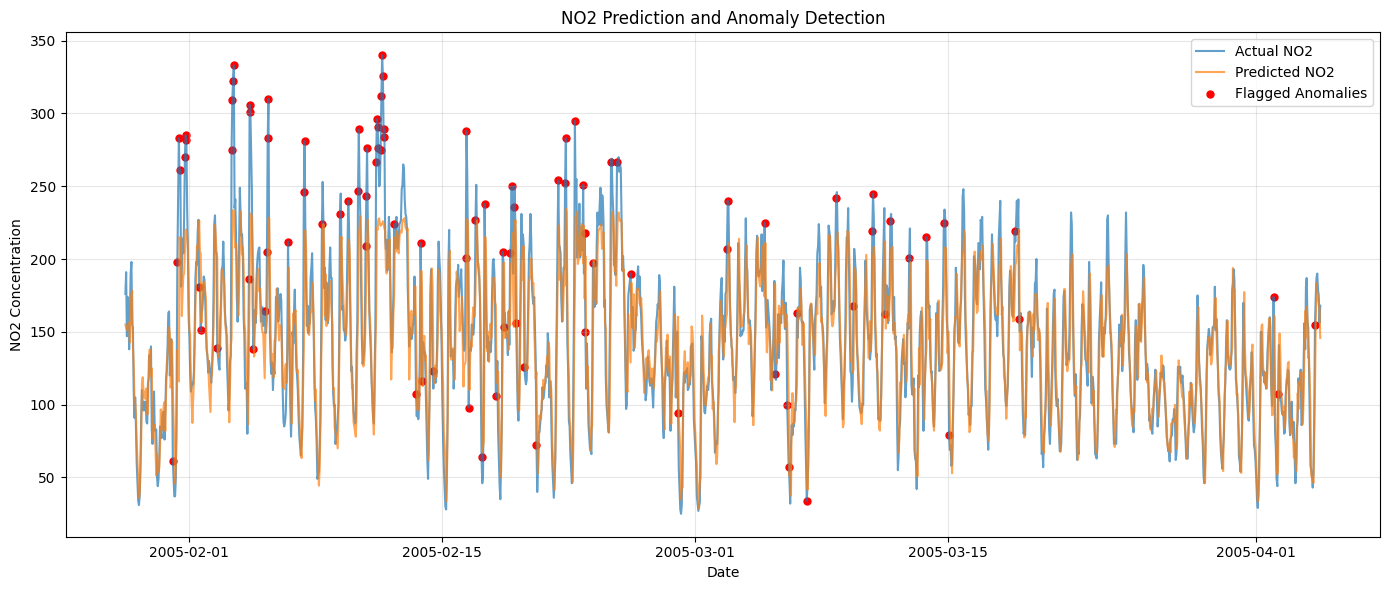

In [32]:

plt.figure(figsize=(14, 6))

plt.plot(
    test_results.index,
    test_results["Actual"],
    label="Actual NO2",
    alpha=0.7
)

plt.plot(
    test_results.index,
    test_results["Predicted"],
    label="Predicted NO2",
    alpha=0.7
)

anomalies = test_results[
    test_results["Anomaly"]
]

plt.scatter(
    anomalies.index,
    anomalies["Actual"],
    color="red",
    label="Flagged Anomalies",
    s=25
)

plt.title("NO2 Prediction and Anomaly Detection")
plt.xlabel("Date")
plt.ylabel("NO2 Concentration")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [33]:

analysis = test_results.copy()

# Identify gaps between consecutive observed hours
hour_gap = (
    analysis.index.to_series()
    .diff()
    .ne(pd.Timedelta(hours=1))
)

# Start a new group when a flag changes
# or the timestamp is not consecutive
new_group = (
    analysis["High_Deviation"].ne(
        analysis["High_Deviation"].shift()
    ) | hour_gap
)

analysis["Group"] = new_group.cumsum()

episodes = (
    analysis[analysis["High_Deviation"]]
    .groupby("Group")
    .agg(
        Start=("Actual", lambda x: x.index.min()),
        End=("Actual", lambda x: x.index.max()),
        Observations=("Actual", "size"),
        Peak_NO2=("Actual", "max"),
        Mean_Residual=("Residual", "mean"),
        Max_Residual=("Residual", "max")
    )
)

display(episodes)


,Start,End,Observations,Peak_NO2,Mean_Residual,Max_Residual
Group,,,,,,
5,2005-01-31 08:00:00,2005-01-31 08:00:00,1,198.0,60.461690,60.461690
6,2005-01-31 10:00:00,2005-01-31 10:00:00,1,283.0,167.036142,167.036142
8,2005-01-31 12:00:00,2005-01-31 12:00:00,1,261.0,51.022848,51.022848
10,2005-01-31 18:00:00,2005-01-31 20:00:00,3,285.0,63.788249,64.681725
15,2005-02-03 08:00:00,2005-02-03 11:00:00,4,333.0,99.062840,129.646423
18,2005-02-04 07:00:00,2005-02-04 09:00:00,3,306.0,79.010847,120.714584
20,2005-02-05 04:00:00,2005-02-05 04:00:00,1,164.0,45.846677,45.846677
22,2005-02-05 07:00:00,2005-02-05 09:00:00,3,310.0,73.304800,91.114709
25,2005-02-06 11:00:00,2005-02-06 11:00:00,1,212.0,60.570140,60.570140


In [34]:

investigation = test_results.copy()

investigation["Missing_Features"] = (
    X_test.isna().sum(axis=1)
)

investigation["Hour"] = investigation.index.hour

investigation["Temperature_Previous_Hour"] = (
    X_test["T_lag_1"]
)

investigation["Humidity_Previous_Hour"] = (
    X_test["RH_lag_1"]
)

flagged_report = investigation[
    investigation["Anomaly"]
].sort_values(
    "Absolute_Error",
    ascending=False
)

display(flagged_report.head(20))


,Actual,Predicted,Residual,Absolute_Error,Anomaly,High_Deviation,Missing_Features,Hour,Temperature_Previous_Hour,Humidity_Previous_Hour
Datetime,,,,,,,,,,
2005-01-31 10:00:00,283.0,115.963858,167.036142,167.036142,True,True,1,10,4.4,38.8
2005-02-03 08:00:00,275.0,145.353577,129.646423,129.646423,True,True,0,8,1.3,63.1
2005-02-04 08:00:00,306.0,185.285416,120.714584,120.714584,True,True,0,8,1.8,73.7
2005-02-11 16:00:00,340.0,223.873777,116.126223,116.126223,True,True,5,16,NaN,NaN
2005-02-22 08:00:00,295.0,179.100897,115.899103,115.899103,True,True,0,8,3.4,84.5
2005-02-07 08:00:00,246.0,140.038155,105.961845,105.961845,True,True,0,8,3.4,47.0
2005-02-11 08:00:00,267.0,161.802915,105.197085,105.197085,True,True,5,8,NaN,NaN
2005-02-11 17:00:00,326.0,225.949252,100.050748,100.050748,True,True,5,17,NaN,NaN
2005-02-03 11:00:00,333.0,233.425576,99.574424,99.574424,True,True,0,11,5.1,50.8


In [35]:

import joblib
import json
import os

output_dir = "/kaggle/working/air_quality_model"

os.makedirs(output_dir, exist_ok=True)

model_path = os.path.join(
    output_dir,
    "no2_prediction_pipeline.joblib"
)

joblib.dump(final_model, model_path)

config = {
    "model_name": final_name,
    "target": target,
    "features": features,
    "forecast_horizon_hours": 1,
    "anomaly_threshold": float(threshold),
    "threshold_method": "95th percentile of validation absolute residuals",
    "test_mae": float(test_mae),
    "test_rmse": float(test_rmse),
    "test_r2": float(test_r2)
}

config_path = os.path.join(
    output_dir,
    "model_config.json"
)

with open(config_path, "w") as file:
    json.dump(config, file, indent=4)

print("Model saved:", model_path)
print("Configuration saved:", config_path)


Model saved: /kaggle/working/air_quality_model/no2_prediction_pipeline.joblib
Configuration saved: /kaggle/working/air_quality_model/model_config.json


In [36]:

test_results.to_csv(
    os.path.join(
        output_dir,
        "anomaly_detection_results.csv"
    )
)

episodes.to_csv(
    os.path.join(
        output_dir,
        "pollution_episodes.csv"
    )
)

print("Anomaly analysis files saved")


Anomaly analysis files saved


In [37]:

loaded_model = joblib.load(model_path)

sample = X_test.iloc[[0]]

original_prediction = final_model.predict(sample)
loaded_prediction = loaded_model.predict(sample)

print("Original prediction:", original_prediction[0])
print("Loaded prediction:", loaded_prediction[0])

assert np.allclose(
    original_prediction,
    loaded_prediction
)

print("Model verification successful!")


Original prediction: 155.01371512082622
Loaded prediction: 155.01371512082625
Model verification successful!
